# Dataset Inspection: Trash Detection (Roboflow, COCO format)

This notebook does the sanity checks before training: split sizes, class balance, box sizes, duplicate/leakage checks, label errors, and visual inspection of boxes. Run the cells top to bottom. Save the printed numbers and figures, since they go into the "Dataset Description and Preprocessing" section of the report.

## 1. Setup and locate the dataset

In [1]:
import json, os, glob, re, hashlib, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

In [2]:
!pip install -q roboflow

from roboflow import Roboflow
from google.colab import userdata

rf = Roboflow(api_key="")
project = rf.workspace("princesss-workspace-2dq44").project("trash-detection-kcsnu-1kabv")
version = project.version(1)
dataset = version.download("coco")

ROOT = dataset.location
SPLITS = [s for s in ["train", "valid", "val", "test"]
          if os.path.exists(f"{ROOT}/{s}/_annotations.coco.json")]
print("Dataset root:", ROOT)
print("Splits found:", SPLITS)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 61.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.6 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Trash-Detection-1 in coco:: 100%|██████████| 2528/2528 [00:00<00:00, 8561.31it/s]


Dataset root: /content/Trash-Detection-1
Splits found: ['train', 'valid', 'test']


## 2. Load the COCO annotations into DataFrames

In [3]:
raw = {}
for s in SPLITS:
    with open(f"{ROOT}/{s}/_annotations.coco.json") as f:
        raw[s] = json.load(f)

# Category map (Roboflow often adds a parent/supercategory entry with no boxes)
cats = {c["id"]: c["name"] for c in raw[SPLITS[0]]["categories"]}
for s in SPLITS[1:]:
    other = {c["id"]: c["name"] for c in raw[s]["categories"]}
    assert other == cats, f"Category mismatch between {SPLITS[0]} and {s}"
print("Categories in file:", cats)

img_rows, ann_rows = [], []
for s in SPLITS:
    imgs = {im["id"]: im for im in raw[s]["images"]}
    for im in imgs.values():
        img_rows.append(dict(split=s, image_id=im["id"], file_name=im["file_name"],
                             img_w=im["width"], img_h=im["height"]))
    for a in raw[s]["annotations"]:
        im = imgs[a["image_id"]]
        x, y, w, h = a["bbox"]
        ann_rows.append(dict(split=s, image_id=a["image_id"], file_name=im["file_name"],
                             category=cats[a["category_id"]], x=x, y=y, w=w, h=h,
                             img_w=im["width"], img_h=im["height"]))

images = pd.DataFrame(img_rows)
anns = pd.DataFrame(ann_rows)
anns["rel_area"] = (anns.w * anns.h) / (anns.img_w * anns.img_h)
anns["abs_area"] = anns.w * anns.h
print(f"\nTotal images: {len(images)} | Total boxes: {len(anns)}")

Categories in file: {0: 'trash', 1: 'cardboard', 2: 'glass', 3: 'metal', 4: 'paper', 5: 'plastic', 6: 'trash'}

Total images: 2524 | Total boxes: 2538


## 3. Split sizes (your assignment suggests roughly 70 / 15 / 15)

In [4]:
split_tbl = images.groupby("split").size().rename("images").to_frame()
split_tbl["image_%"] = (100 * split_tbl["images"] / split_tbl["images"].sum()).round(1)
split_tbl["boxes"] = anns.groupby("split").size()
split_tbl["boxes_per_image"] = (split_tbl["boxes"] / split_tbl["images"]).round(2)
split_tbl = split_tbl.reindex([s for s in ["train", "valid", "val", "test"] if s in split_tbl.index])
display(split_tbl)

,images,image_%,boxes,boxes_per_image
split,,,,
train,1767,70.0,1773,1.00
valid,379,15.0,383,1.01
test,378,15.0,382,1.01


If the percentages are far from 70/15/15 (Roboflow's default is often 70/20/10), you can either re-split on Roboflow before exporting or explain the actual ratio in your report.

## 4. Class distribution

split,train,valid,test,total,share_%
category,,,,,
paper,435,73,86,594,23.4
glass,347,65,89,501,19.7
plastic,313,86,83,482,19.0
metal,300,61,54,415,16.4
cardboard,284,68,55,407,16.0
trash,94,30,15,139,5.5


Imbalance ratio (largest / smallest class): 4.3x


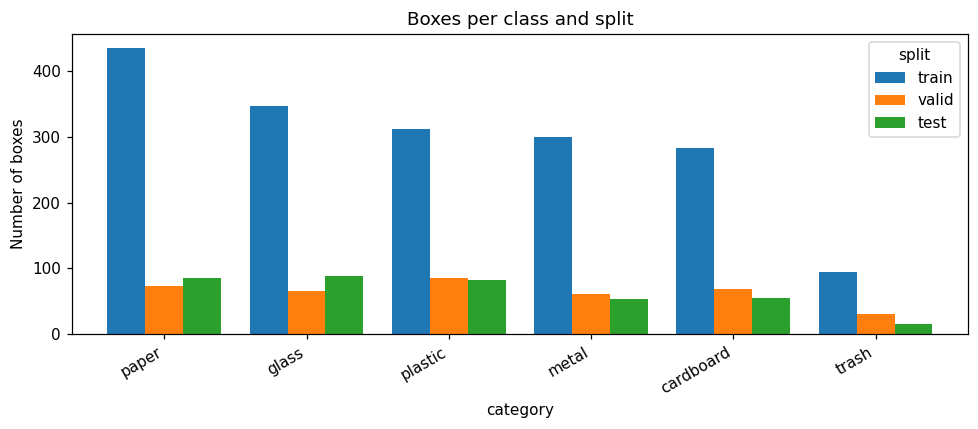

In [5]:
class_tbl = anns.groupby(["category", "split"]).size().unstack(fill_value=0)
class_tbl = class_tbl[[s for s in SPLITS if s in class_tbl.columns]]
class_tbl["total"] = class_tbl.sum(axis=1)
class_tbl["share_%"] = (100 * class_tbl["total"] / class_tbl["total"].sum()).round(1)
class_tbl = class_tbl.sort_values("total", ascending=False)
display(class_tbl)

unused = [n for n in cats.values() if n not in class_tbl.index]
if unused:
    print("Categories with zero boxes (probably a parent/supercategory entry):", unused)

ratio = class_tbl["total"].max() / class_tbl["total"].min()
print(f"Imbalance ratio (largest / smallest class): {ratio:.1f}x")

ax = class_tbl[[s for s in SPLITS if s in class_tbl.columns]].plot(
    kind="bar", figsize=(9, 4), width=0.8)
ax.set_title("Boxes per class and split")
ax.set_ylabel("Number of boxes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Check that every class shows up in valid and test with a reasonable count. A class with only a handful of test boxes will give unstable per-class precision and recall.

## 5. Image sizes and boxes per image

Image resolutions:


,,images
img_w,img_h,
512,384,2524



Boxes per image:


,count,mean,std,min,25%,50%,75%,max
n_boxes,2524.0,1.01,0.1,0.0,1.0,1.0,1.0,2.0


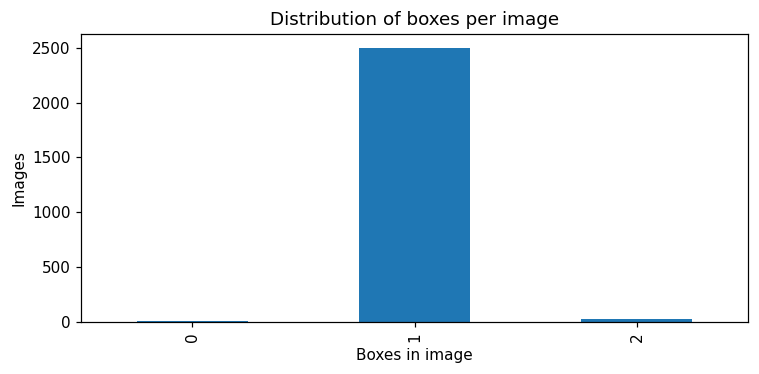

In [6]:
size_tbl = images.groupby(["img_w", "img_h"]).size().sort_values(ascending=False).rename("images")
print("Image resolutions:")
display(size_tbl.head(10).to_frame())

per_img = anns.groupby(["split", "image_id"]).size().rename("n_boxes").reset_index()
all_imgs = images.merge(per_img, on=["split", "image_id"], how="left").fillna({"n_boxes": 0})
print("\nBoxes per image:")
display(all_imgs["n_boxes"].describe().round(2).to_frame().T)

fig, ax = plt.subplots(1, 1, figsize=(7, 3.5))
all_imgs["n_boxes"].astype(int).value_counts().sort_index().plot(kind="bar", ax=ax)
ax.set_title("Distribution of boxes per image")
ax.set_xlabel("Boxes in image"); ax.set_ylabel("Images")
plt.tight_layout(); plt.show()

## 6. Box size analysis

This tells you whether the objects are large and isolated or small and hard to detect. COCO's size buckets are based on pixel area at the original image size: small < 32², medium 32² to 96², large > 96². Because your images are probably resized later, the relative area (box area / image area) is the more useful number here.

Box size buckets per class (COCO definition, original resolution):


size_bucket,small,medium,large
category,,,
cardboard,0,1,406
glass,0,2,499
metal,0,5,410
paper,0,0,594
plastic,0,4,478
trash,0,1,138



Relative box area (fraction of image) per class:


,count,mean,25%,50%,75%,max
category,,,,,,
cardboard,407.0,0.892,0.856,1.000,1.000,1.0
glass,501.0,0.424,0.260,0.400,0.564,1.0
metal,415.0,0.474,0.299,0.460,0.630,1.0
paper,594.0,0.679,0.524,0.723,0.870,1.0
plastic,482.0,0.520,0.345,0.502,0.701,1.0
trash,139.0,0.427,0.213,0.382,0.584,1.0


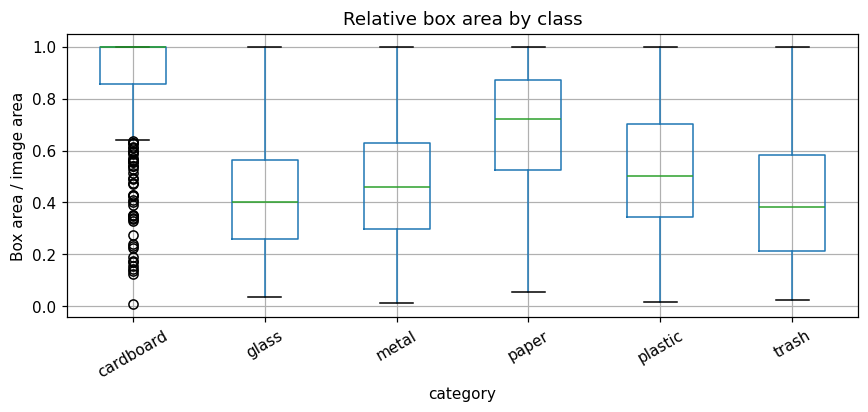

In [7]:
def coco_bucket(a):
    return "small" if a < 32**2 else ("medium" if a < 96**2 else "large")

anns["size_bucket"] = anns["abs_area"].apply(coco_bucket)
bucket_tbl = anns.groupby(["category", "size_bucket"]).size().unstack(fill_value=0)
bucket_tbl = bucket_tbl.reindex(columns=["small", "medium", "large"], fill_value=0)
print("Box size buckets per class (COCO definition, original resolution):")
display(bucket_tbl)

print("\nRelative box area (fraction of image) per class:")
display(anns.groupby("category")["rel_area"].describe()[["count", "mean", "25%", "50%", "75%", "max"]].round(3))

fig, ax = plt.subplots(figsize=(8, 4))
anns.boxplot(column="rel_area", by="category", ax=ax, rot=30)
ax.set_title("Relative box area by class"); plt.suptitle("")
ax.set_ylabel("Box area / image area")
plt.tight_layout(); plt.show()

## 7. Label sanity checks

Looks for boxes that are zero-sized, fall outside the image, or are extremely thin, plus images with no annotations at all.

In [8]:
tol = 1.0  # pixel tolerance
bad_size = anns[(anns.w <= 1) | (anns.h <= 1)]
out_of_bounds = anns[(anns.x < -tol) | (anns.y < -tol) |
                     (anns.x + anns.w > anns.img_w + tol) |
                     (anns.y + anns.h > anns.img_h + tol)]
aspect = anns.w / anns.h.replace(0, np.nan)
extreme_aspect = anns[(aspect > 10) | (aspect < 0.1)]
no_boxes = all_imgs[all_imgs.n_boxes == 0]

print(f"Boxes with width or height <= 1 px : {len(bad_size)}")
print(f"Boxes outside image bounds         : {len(out_of_bounds)}")
print(f"Boxes with extreme aspect ratio    : {len(extreme_aspect)}")
print(f"Images with no annotations         : {len(no_boxes)} ({100*len(no_boxes)/len(images):.1f}%)")

# Exact duplicate boxes inside the same image
dups = anns.duplicated(subset=["split", "file_name", "category", "x", "y", "w", "h"]).sum()
print(f"Exact duplicate boxes              : {dups}")

Boxes with width or height <= 1 px : 0
Boxes outside image bounds         : 0
Boxes with extreme aspect ratio    : 0
Images with no annotations         : 5 (0.2%)
Exact duplicate boxes              : 0


## 8. Duplicate and leakage check across splits

Two checks: (1) identical file contents (MD5), and (2) the same original source image, using the name Roboflow keeps before `.rf.` in each filename. Any overlap between train and valid/test inflates your results and should be removed.

In [9]:
def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

images["path"] = images.apply(lambda r: f"{ROOT}/{r.split}/{r.file_name}", axis=1)
images["md5"] = images["path"].apply(md5)
images["source_name"] = images["file_name"].str.split(".rf.").str[0]

def overlap_report(col):
    sets = {s: set(images.loc[images.split == s, col]) for s in SPLITS}
    print(f"Overlap by {col}:")
    pairs = [(a, b) for i, a in enumerate(SPLITS) for b in SPLITS[i + 1:]]
    for a, b in pairs:
        print(f"  {a:>5} vs {b:<5}: {len(sets[a] & sets[b])}")

overlap_report("md5")
print()
overlap_report("source_name")

within = images.duplicated(subset="md5", keep=False).sum()
print(f"\nImages sharing identical content with another image (any split): {within}")

Overlap by md5:
  train vs valid: 0
  train vs test : 0
  valid vs test : 0

Overlap by source_name:
  train vs valid: 0
  train vs test : 0
  valid vs test : 0

Images sharing identical content with another image (any split): 0


If the overlap counts are 0, you can state in the report that no leakage was detected. If not, list the duplicates and drop them from valid/test before evaluation.

## 9. Visual check: random images with boxes

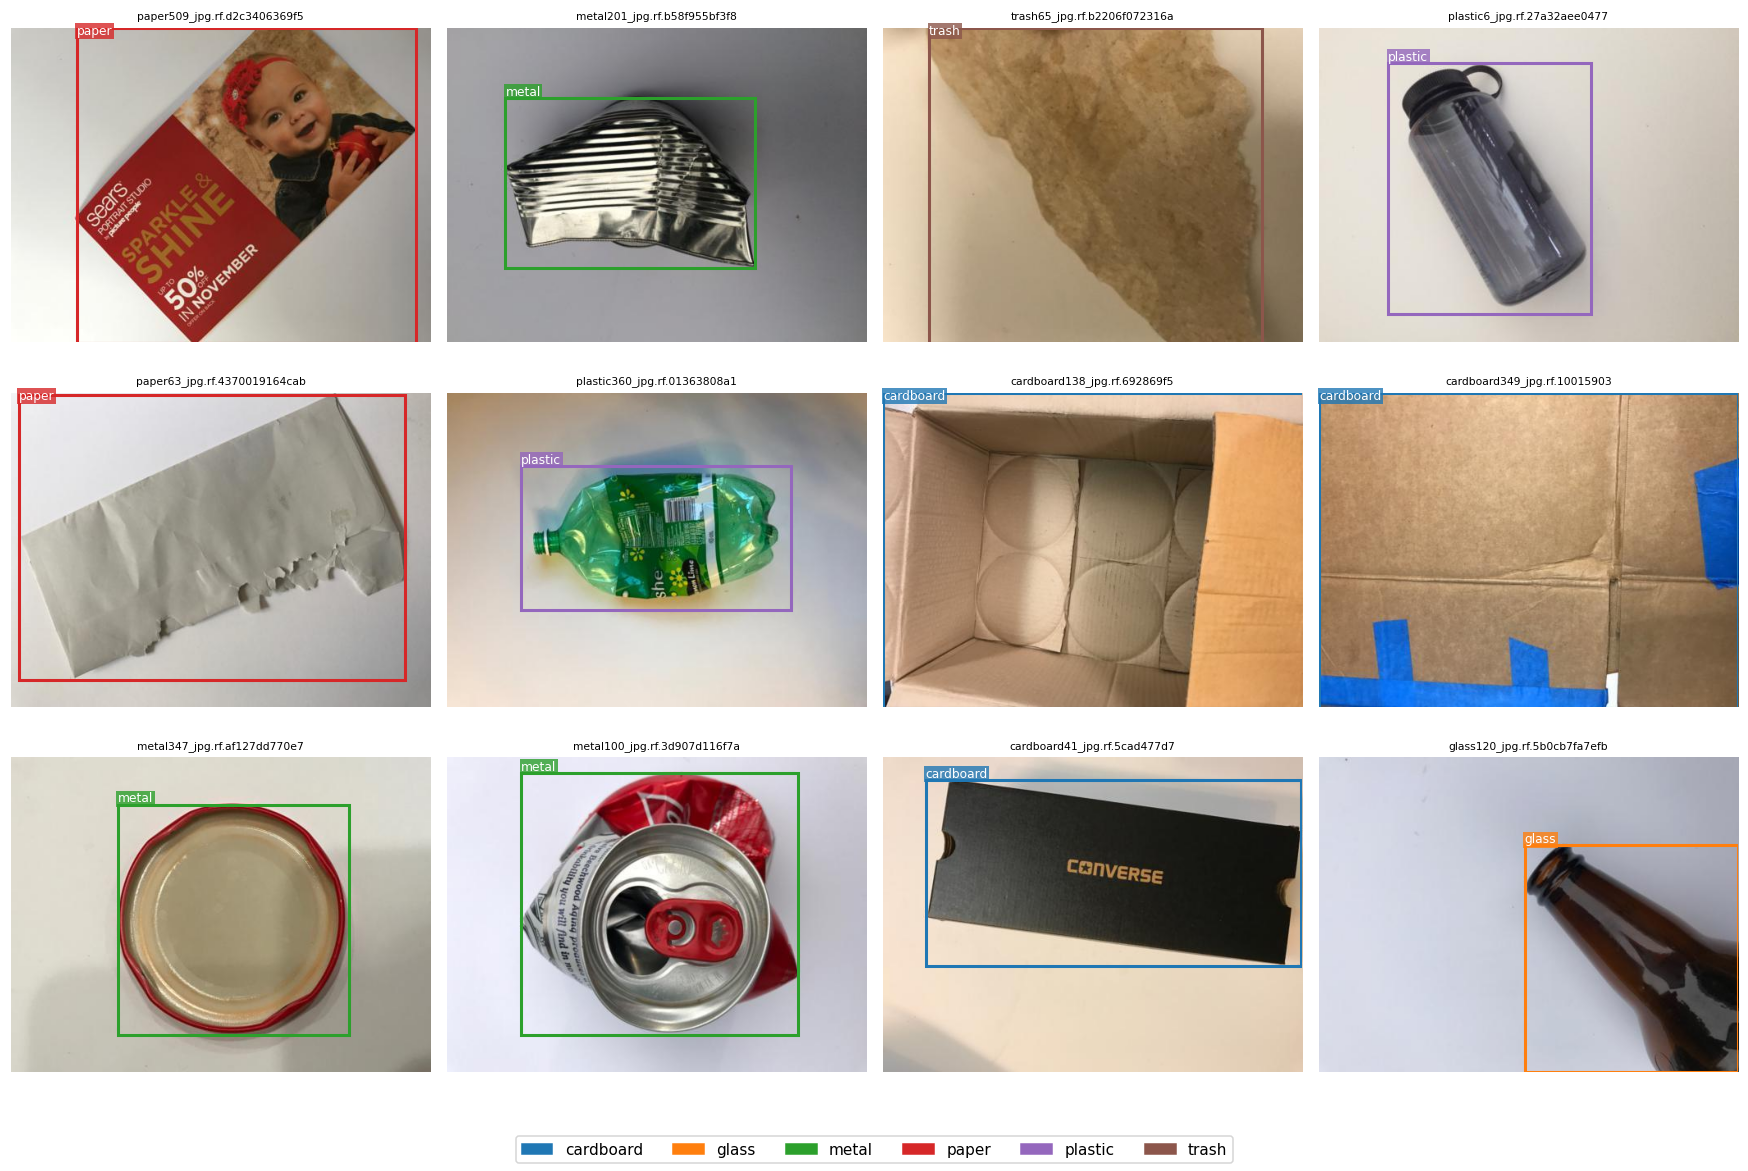

In [10]:
palette = plt.cm.tab10(np.linspace(0, 1, 10))
cat_names = sorted(anns["category"].unique())
cat_color = {c: palette[i % 10] for i, c in enumerate(cat_names)}

def draw_samples(split="train", n=12, cols=4, seed=0, only_class=None):
    df = anns[anns.split == split]
    if only_class:
        df = df[df.category == only_class]
    files = df["file_name"].unique().tolist()
    random.Random(seed).shuffle(files)
    files = files[:n]
    rows = int(np.ceil(len(files) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.6 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, fn in zip(axes, files):
        im = Image.open(f"{ROOT}/{split}/{fn}").convert("RGB")
        ax.imshow(im)
        for _, r in anns[(anns.split == split) & (anns.file_name == fn)].iterrows():
            ax.add_patch(patches.Rectangle((r.x, r.y), r.w, r.h, fill=False,
                                           edgecolor=cat_color[r.category], linewidth=2))
            ax.text(r.x, max(r.y - 3, 8), r.category, fontsize=8, color="white",
                    bbox=dict(facecolor=cat_color[r.category], alpha=0.8, pad=1, edgecolor="none"))
        ax.set_title(fn[:28], fontsize=7)
    handles = [patches.Patch(color=cat_color[c], label=c) for c in cat_names]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles))
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

draw_samples("train", n=12, seed=0)

Run again with a different `seed` to see other images. Aim to look at 20 to 30 images in total. Things to note: loose or tight boxes, missed objects, mislabeled classes, and whether the scenes are plain backgrounds or messy real-world scenes.

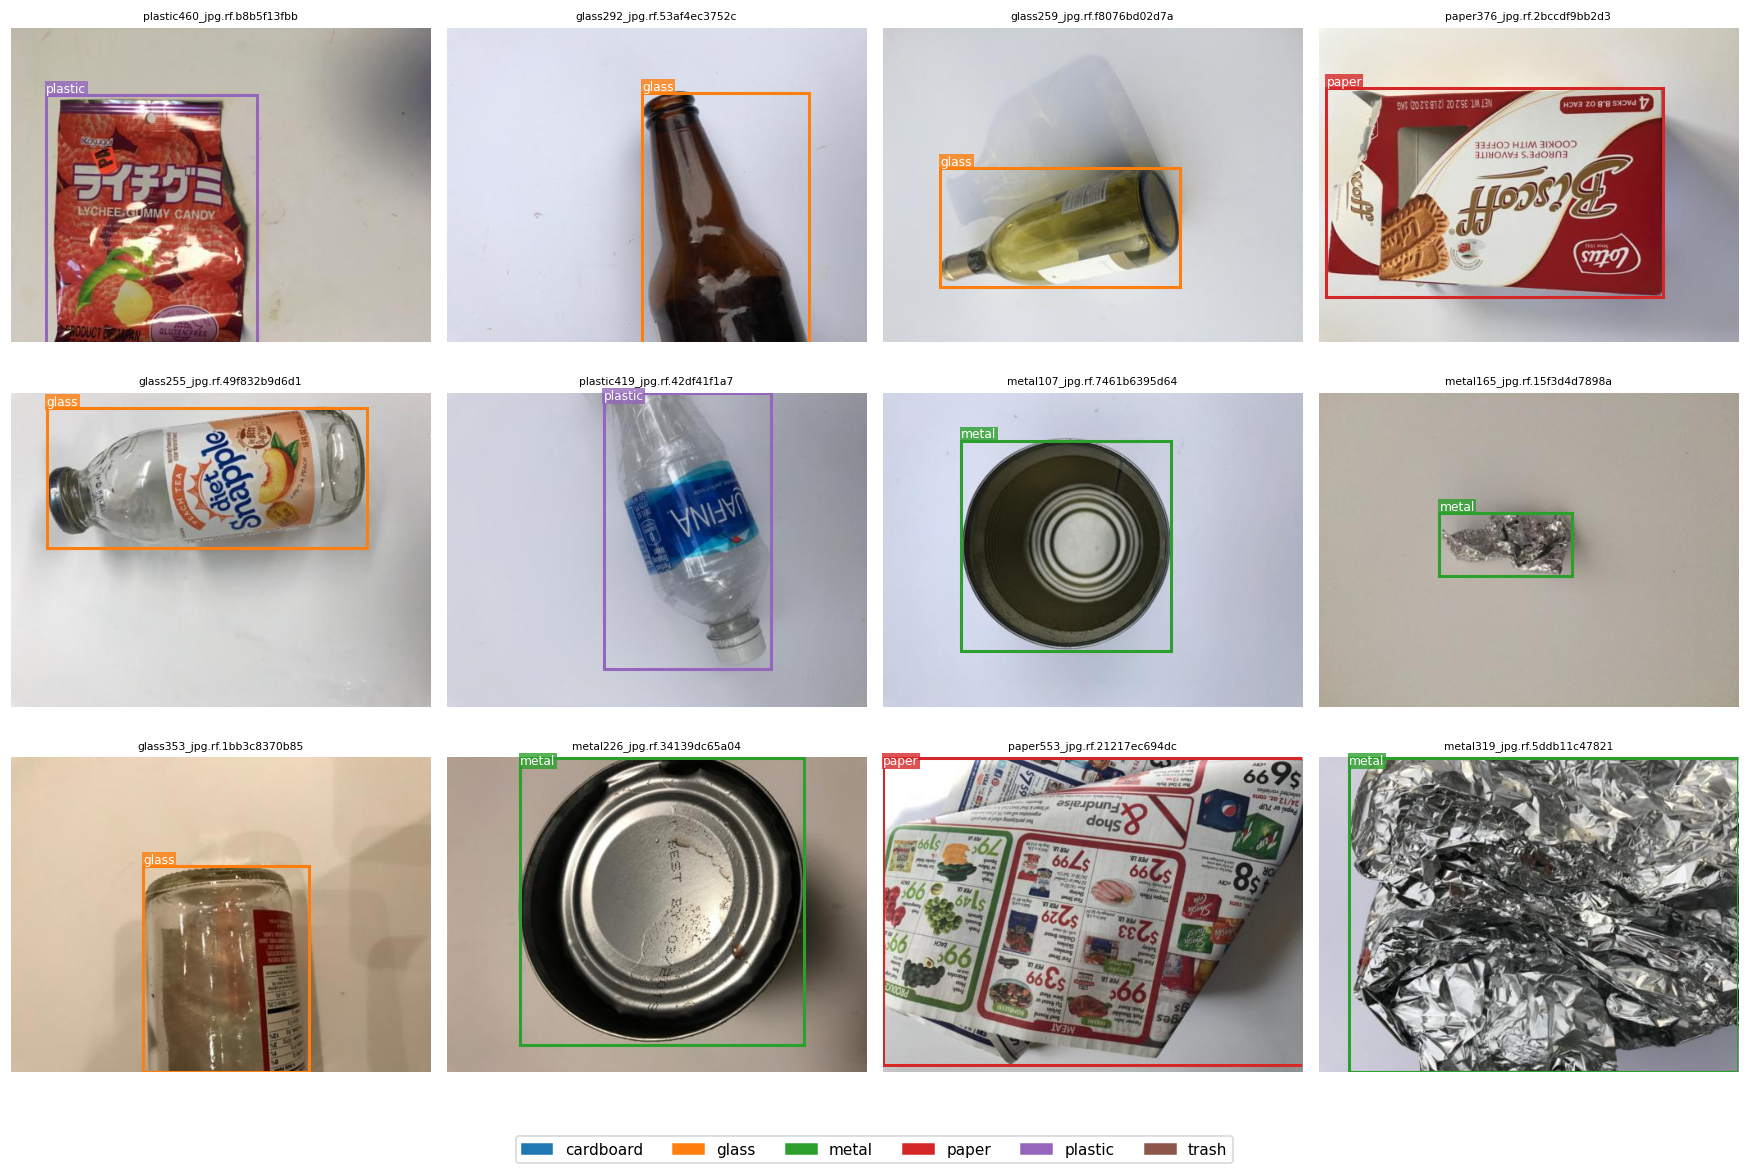

In [11]:
draw_samples('train', n=12, seed=1)

### The ambiguous `trash` class

This is the catch-all class, so look at it separately and decide how to describe it in your report.

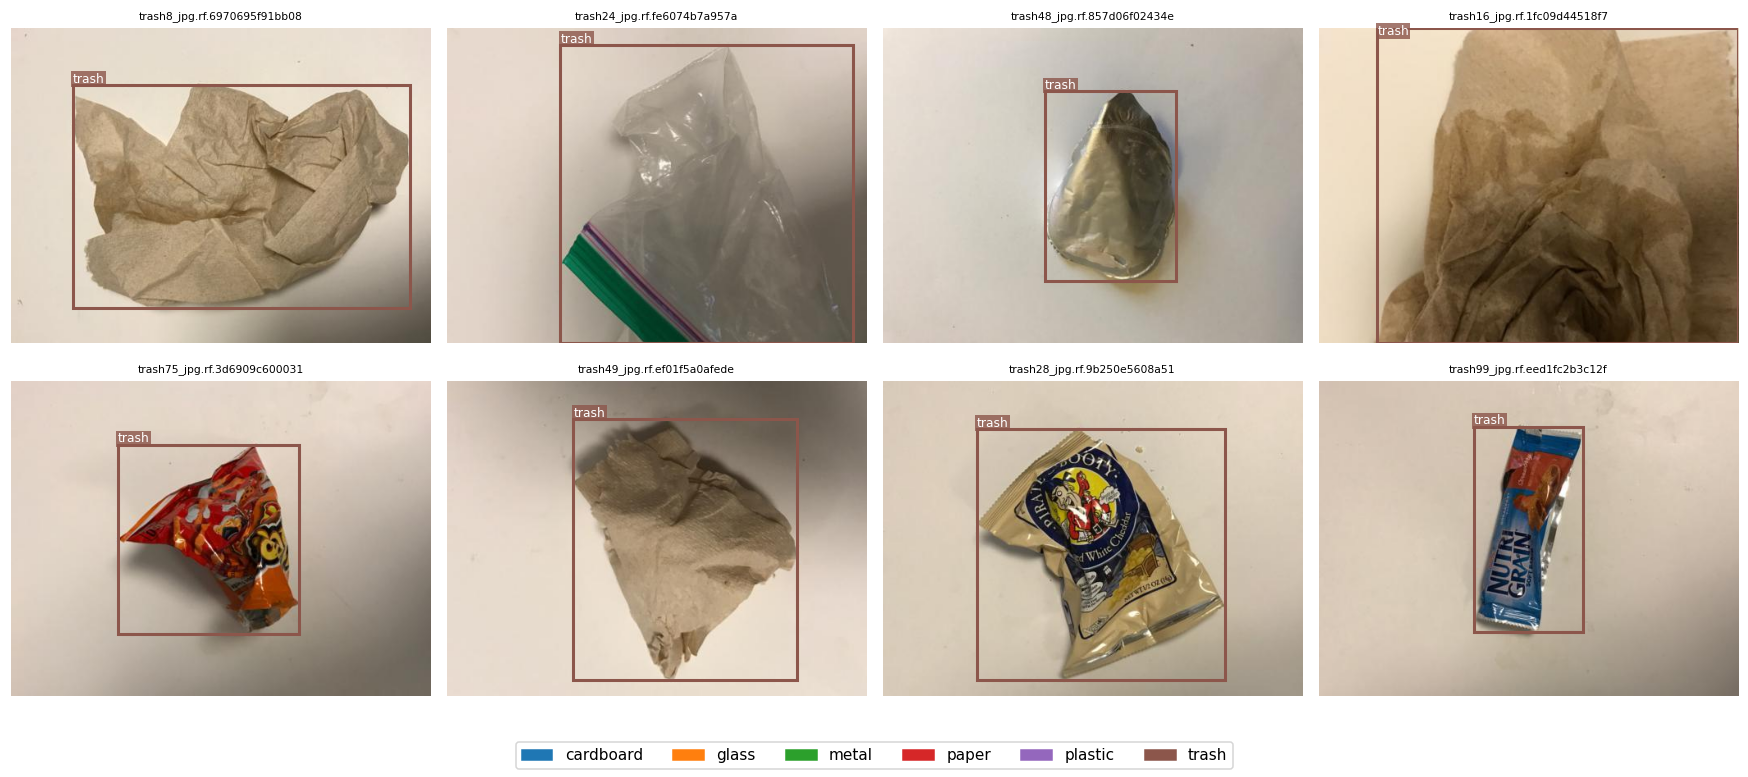

In [12]:
draw_samples("train", n=8, cols=4, seed=0, only_class="trash")

### Check a test-set sample too

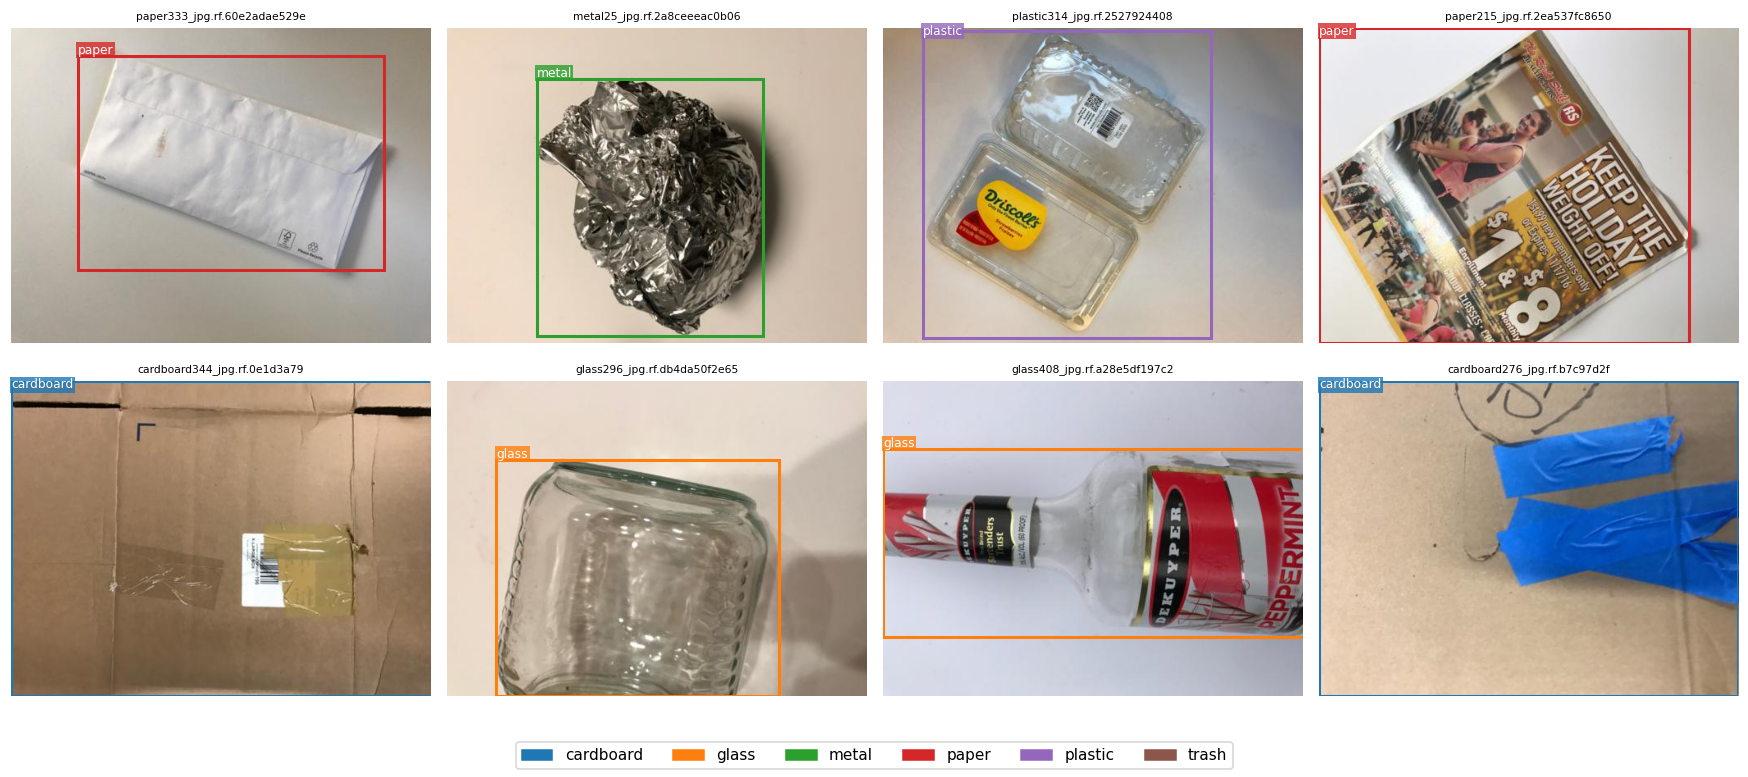

In [13]:
draw_samples("test" if "test" in SPLITS else SPLITS[-1], n=8, cols=4, seed=0)

## 10. Summary for the report

In [14]:
print("=== DATASET SUMMARY ===")
print(f"Root folder      : {ROOT}")
print(f"Images           : {len(images)}  ({', '.join(f'{s}: {n}' for s, n in images.groupby('split').size().items())})")
print(f"Boxes            : {len(anns)}  (avg {len(anns)/len(images):.2f} per image)")
print(f"Classes          : {len(class_tbl)} -> {', '.join(class_tbl.index)}")
print(f"Imbalance ratio  : {ratio:.1f}x")
print(f"Image sizes      : {size_tbl.index[0]} is the most common ({size_tbl.iloc[0]} images)")
print(f"Median rel. area : {anns.rel_area.median():.3f} of image")
print(f"Small/Med/Large  : {anns.size_bucket.value_counts().to_dict()}")
print(f"Label issues     : {len(bad_size)} tiny, {len(out_of_bounds)} out-of-bounds, {len(no_boxes)} unlabeled images")
print(f"Leakage (md5)    : {sum(len(set(images.loc[images.split==a,'md5']) & set(images.loc[images.split==b,'md5'])) for i,a in enumerate(SPLITS) for b in SPLITS[i+1:])} duplicates across splits")

=== DATASET SUMMARY ===
Root folder      : /content/Trash-Detection-1
Images           : 2524  (test: 378, train: 1767, valid: 379)
Boxes            : 2538  (avg 1.01 per image)
Classes          : 6 -> paper, glass, plastic, metal, cardboard, trash
Imbalance ratio  : 4.3x
Image sizes      : (np.int64(512), np.int64(384)) is the most common (2524 images)
Median rel. area : 0.571 of image
Small/Med/Large  : {'large': 2525, 'medium': 13}
Label issues     : 0 tiny, 0 out-of-bounds, 5 unlabeled images
Leakage (md5)    : 0 duplicates across splits
